# EfficientNet-B0 teacher model training

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import json

In [2]:
torch.manual_seed(42)
np.random.seed(42)

data_dir = '/kaggle/input/datasets/nirmalsankalana/potato-leaf-disease-dataset'
num_classes = 7
batch_size = 32
num_epochs = 50
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device {device}")

Using device cuda


In [3]:
seeds = [42, 43, 44, 45, 46]
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

aug_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Read and resize images into RAM
base_folder = datasets.ImageFolder(data_dir)
class_names = base_folder.classes
targets = base_folder.targets

print("Caching images")
cached_pil_images = []
for path, _ in base_folder.samples:
    with Image.open(path) as img:
        cached_pil_images.append(img.convert("RGB").resize((224, 224), Image.BILINEAR))
print(f"Successfully cached {len(cached_pil_images)} images")

class RAMImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[idx]

# Dataset & Stratified Split 
train_full_dataset = RAMImageDataset(cached_pil_images, targets, transform=aug_transforms)
val_full_dataset = RAMImageDataset(cached_pil_images, targets, transform=data_transforms)

# 80/20
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.2, random_state=42, stratify=targets
)

train_dataset = Subset(train_full_dataset, train_idx)
val_dataset = Subset(val_full_dataset, val_idx)

Caching images
Successfully cached 3076 images


In [4]:
def make_sampler(labels, num_classes=7):
    class_sample_count = np.bincount(labels, minlength=num_classes)
    weights = 1.0 / np.sqrt(class_sample_count)
    samples_weight = [weights[label] for label in labels]
    return WeightedRandomSampler(weights=samples_weight, num_samples=len(samples_weight), replacement=True)

train_labels = [targets[i] for i in train_idx]

In [5]:
class EfficientNet(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.base_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        
        in_features = self.base_model.classifier[1].in_features
        self.base_model.classifier = nn.Sequential(
            nn.Dropout(p= 0.3, inplace=True),
            nn.Linear(in_features, num_classes)
        )
        
    def forward(self, x):
        return self.base_model(x)

teacher = EfficientNet(num_classes).to(device)
total_params = sum(p.numel() for p in teacher.parameters())
trainable_params = sum(p.numel() for p in teacher.parameters() if p.requires_grad)

print(f"Total parameters in teacher: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 214MB/s]


Total parameters in teacher: 4,016,515
Trainable parameters: 4,016,515


In [6]:
criterion = nn.CrossEntropyLoss()
results = {}

for seed in seeds:
    torch.manual_seed(seed)

    sampler = make_sampler(train_labels, num_classes)
    dataloaders = {
        'Train': DataLoader(train_dataset, batch_size=batch_size,
                            sampler=sampler, num_workers=0),
        'Valid': DataLoader(val_dataset, batch_size=batch_size,
                            shuffle=False, num_workers=0)
    }

    teacher = EfficientNet(num_classes).to(device)

    optimizer = torch.optim.AdamW([
        {'params': teacher.base_model.features.parameters(), 'lr': 1e-4, 'weight_decay': 1e-4},
        {'params': teacher.base_model.classifier.parameters(),  'lr': 1e-3, 'weight_decay': 1e-4}
    ])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda')

    best_val_acc = 0.0
    model_save_path = f'base-effnet_model_seed{seed}.pth' 
    train_losses, val_accs = [], []

    for epoch in range(num_epochs):
        teacher.train()
        total_loss, correct, total = 0, 0, 0

        for inputs, labels in dataloaders['Train']:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda'):
                outputs = teacher(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item() * inputs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        scheduler.step()
        train_loss = total_loss / total
        train_acc = correct / total

        teacher.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for val_inputs, val_labels in dataloaders['Valid']:
                val_inputs, val_labels = val_inputs.to(device), val_labels.to(device)

                with torch.amp.autocast('cuda'):
                    val_outputs = teacher(val_inputs)
                val_preds = val_outputs.argmax(dim=1)
                val_correct += (val_preds == val_labels).sum().item()
                val_total += val_labels.size(0)

        val_acc = val_correct / val_total
        train_losses.append(train_loss)
        val_accs.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(teacher.state_dict(), model_save_path)
        if (epoch + 1) % 10 == 0:
            print(f"seed {seed} | epoch {epoch + 1}: train_loss = {train_loss:.4f} | train_acc = {train_acc:.4f} | val_acc = {val_acc:.4f}")

    results[seed] = dict(best=best_val_acc, last=val_acc, train_loss=train_losses, val_acc=val_accs)
    print(f"seed {seed}: best {best_val_acc:.4f} | last {val_acc:.4f}\n")

seed 42 | epoch 10: train_loss = 0.2123 | train_acc = 0.9248 | val_acc = 0.8490
seed 42 | epoch 20: train_loss = 0.0865 | train_acc = 0.9671 | val_acc = 0.8782
seed 42 | epoch 30: train_loss = 0.0597 | train_acc = 0.9801 | val_acc = 0.8620
seed 42 | epoch 40: train_loss = 0.0385 | train_acc = 0.9854 | val_acc = 0.8766
seed 42 | epoch 50: train_loss = 0.0399 | train_acc = 0.9870 | val_acc = 0.8669
seed 42: best 0.8880 | last 0.8669

seed 43 | epoch 10: train_loss = 0.2039 | train_acc = 0.9293 | val_acc = 0.8636
seed 43 | epoch 20: train_loss = 0.0959 | train_acc = 0.9699 | val_acc = 0.8701
seed 43 | epoch 30: train_loss = 0.0604 | train_acc = 0.9780 | val_acc = 0.8945
seed 43 | epoch 40: train_loss = 0.0437 | train_acc = 0.9862 | val_acc = 0.8847
seed 43 | epoch 50: train_loss = 0.0341 | train_acc = 0.9911 | val_acc = 0.8880
seed 43: best 0.8961 | last 0.8880

seed 44 | epoch 10: train_loss = 0.1764 | train_acc = 0.9366 | val_acc = 0.8555
seed 44 | epoch 20: train_loss = 0.0926 | train_

Classification Report:

              precision    recall  f1-score   support

    Bacteria     1.0000    0.9649    0.9821       114
       Fungi     0.8759    0.8467    0.8610       150
     Healthy     0.8478    0.9750    0.9070        40
    Nematode     0.7273    0.5714    0.6400        14
        Pest     0.8264    0.8197    0.8230       122
 Phytopthora     0.8243    0.8841    0.8531        69
       Virus     0.9358    0.9533    0.9444       107

    accuracy                         0.8880       616
   macro avg     0.8625    0.8593    0.8587       616
weighted avg     0.8885    0.8880    0.8875       616



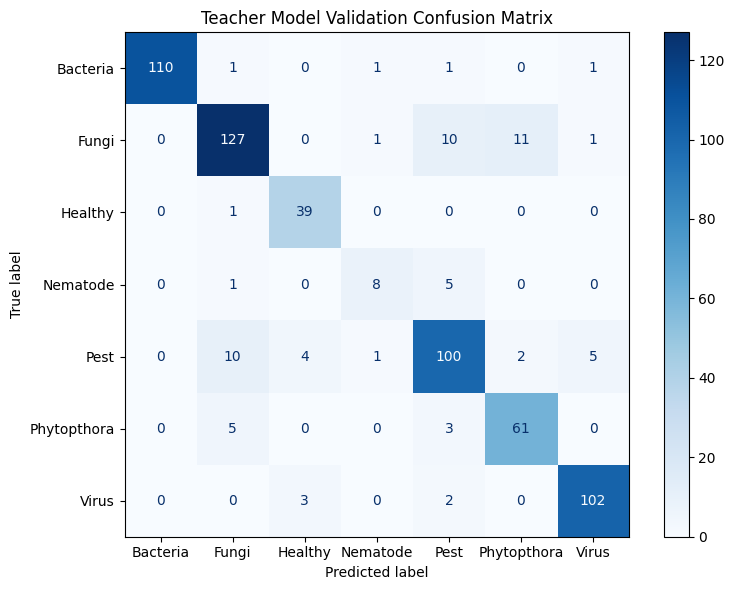

In [7]:
class_names = base_folder.classes

# seed 42 model used as teacher.
load_path = "base-effnet_model_seed42.pth"
teacher.load_state_dict(torch.load(load_path, map_location=device, weights_only=True))
teacher.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for val_inputs, val_labels in dataloaders['Valid']:
        val_inputs = val_inputs.to(device)
        preds = teacher(val_inputs).argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(val_labels.numpy())

print("Classification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

plt.figure(figsize=(8, 6))
disp.plot(cmap="Blues", values_format="d", ax=plt.gca())
plt.title("Teacher Model Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [8]:
with open("teacher_results.json", "w") as f:
    json.dump(results, f, indent=2)

best = np.array([results[s]["best"] for s in seeds]) * 100
last = np.array([results[s]["last"] for s in seeds]) * 100

for s, b, l in zip(seeds, best, last):
    print(f"seed {s} | best: {b:.2f}% | last: {l:.2f}%")
print(f"mean   | best: {best.mean():.2f} +/- {best.std(ddof=1):.2f}% | last: {last.mean():.2f} +/- {last.std(ddof=1):.2f}%")

seed 42 | best: 88.80% | last: 86.69%
seed 43 | best: 89.61% | last: 88.80%
seed 44 | best: 89.12% | last: 88.47%
seed 45 | best: 88.96% | last: 88.47%
seed 46 | best: 89.29% | last: 87.50%
mean   | best: 89.16 +/- 0.31% | last: 87.99 +/- 0.87%


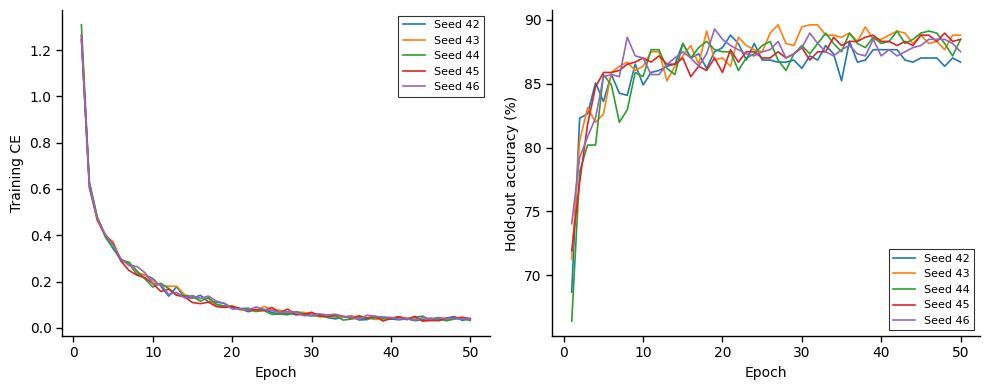

In [9]:
epochs = np.arange(1, num_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

for s in seeds:
    ax1.plot(epochs, results[s]["train_loss"], lw=1.2, label=f"Seed {s}")
    ax2.plot(epochs, np.array(results[s]["val_acc"]) * 100, lw=1.2, label=f"Seed {s}")

ax1.set_ylabel("Training CE")
ax2.set_ylabel("Hold-out accuracy (%)")

for ax, loc in ((ax1, "upper right"), (ax2, "lower right")):
    ax.set_xlabel("Epoch")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    ax.tick_params(direction="out", which="major", length=4, width=1.0)
    ax.minorticks_off()
    leg = ax.legend(loc=loc, frameon=True, fancybox=False, edgecolor="black", fontsize=8)
    leg.get_frame().set_linewidth(0.8)

fig.tight_layout()
fig.savefig("teacher_curves.png", dpi=300, bbox_inches="tight")
plt.show()